<a href="https://colab.research.google.com/github/Shreyask28/House_Prices_Analysis/blob/main/EDA_House_Prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ***EXPLORATORY ANALYSIS OF HOUSE PRICES***

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt,seaborn as sns,scipy.stats as stats

importing training dataset

In [3]:
df = pd.read_csv('/content/train.csv')

In [4]:
df

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


the dataset have 1460 X 81 shape, and PoolQc has highest missing percentage of values

In [15]:
print(df.shape)
print(df.head())
df.info()
missing = df.isnull().sum()
missing = missing.sort_values(ascending=False)
missing_percentage = (missing / len(df)) * 100
print("\n")
missing_summary = pd.DataFrame({
    'Missing Values': missing,
    'Missing Percentage': missing_percentage
})

missing_summary = missing_summary[missing_summary['Missing Values'] > 0]

print(missing_summary)

(1460, 81)
   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0   2008  

In [34]:
numeric_cols = df.select_dtypes(int).columns
print(numeric_cols)
print("\n")
categorical_cols = df.select_dtypes(object).columns
print(categorical_cols)
ordinal_map = {
    'ExterQual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
    'KitchenQual': ['Po', 'Fa', 'TA', 'Gd', 'Ex'],

}
for column in ordinal_map:
    df[column] = pd.Categorical(
        df[column],
        categories=ordinal_map[column],
        ordered=True
    )

    # 1. Identify numerical columns
numeric_cols = df.select_dtypes(include='number').columns

# 2. Identify categorical columns
categorical_cols = df.select_dtypes(include='object').columns

# 3. Define ordinal mapping
ordinal_map = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"]
}

# 4. Convert ordinal columns
for column in ordinal_map:
    df[column] = pd.Categorical(
        df[column],
        categories=ordinal_map[column],
        ordered=True
    )

# 5. Build summary table
summary = []

for column in df.columns:

    if column in ordinal_map:
        col_type = "Ordinal"
    elif column in numeric_cols:
        col_type = "Numerical"
    elif column in categorical_cols:
        col_type = "Categorical"
    else:
        col_type = "Other"

    summary.append({
        "Column Name": column,
        "Type": col_type,
        "Unique Values": df[column].nunique(),
        "Example Values": df[column].dropna().unique()[:5].tolist()
    })

# 6. Display summary
summary_df = pd.DataFrame(summary)
display(summary_df)




Index(['Id', 'MSSubClass', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
       'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea',
       'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr',
       'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars',
       'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch',
       'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='object')


Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', 'Functional', 'Firepla

,Column Name,Type,Unique Values,Example Values
0,Id,Numerical,1460,"[1, 2, 3, 4, 5]"
1,MSSubClass,Numerical,15,"[60, 20, 70, 50, 190]"
2,MSZoning,Categorical,5,"[RL, RM, C (all), FV, RH]"
3,LotFrontage,Numerical,110,"[65.0, 80.0, 68.0, 60.0, 84.0]"
4,LotArea,Numerical,1073,"[8450, 9600, 11250, 9550, 14260]"
...,...,...,...,...
76,MoSold,Numerical,12,"[2, 5, 9, 12, 10]"
77,YrSold,Numerical,5,"[2008, 2007, 2006, 2009, 2010]"
78,SaleType,Categorical,9,"[WD, New, COD, ConLD, ConLI]"
79,SaleCondition,Categorical,6,"[Normal, Abnorml, Partial, AdjLand, Alloca]"


From above output 👆 OverallQual is stored as a number but is really ordinal. Mention this in your notes.

Descriptive Statistics

In [37]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [38]:
for column in ['SalePrice', 'GrLivArea', 'LotArea']:

    mean = df[column].mean()
    median = df[column].median()
    mode = df[column].mode()[0]

    print(f"\nStatistics for {column}")
    print("Mean:", mean)
    print("Median:", median)
    print("Mode:", mode)


Statistics for SalePrice
Mean: 180921.19589041095
Median: 163000.0
Mode: 140000

Statistics for GrLivArea
Mean: 1515.463698630137
Median: 1464.0
Mode: 864

Statistics for LotArea
Mean: 10516.828082191782
Median: 9478.5
Mode: 7200


The Mean > Median

## Distrubution

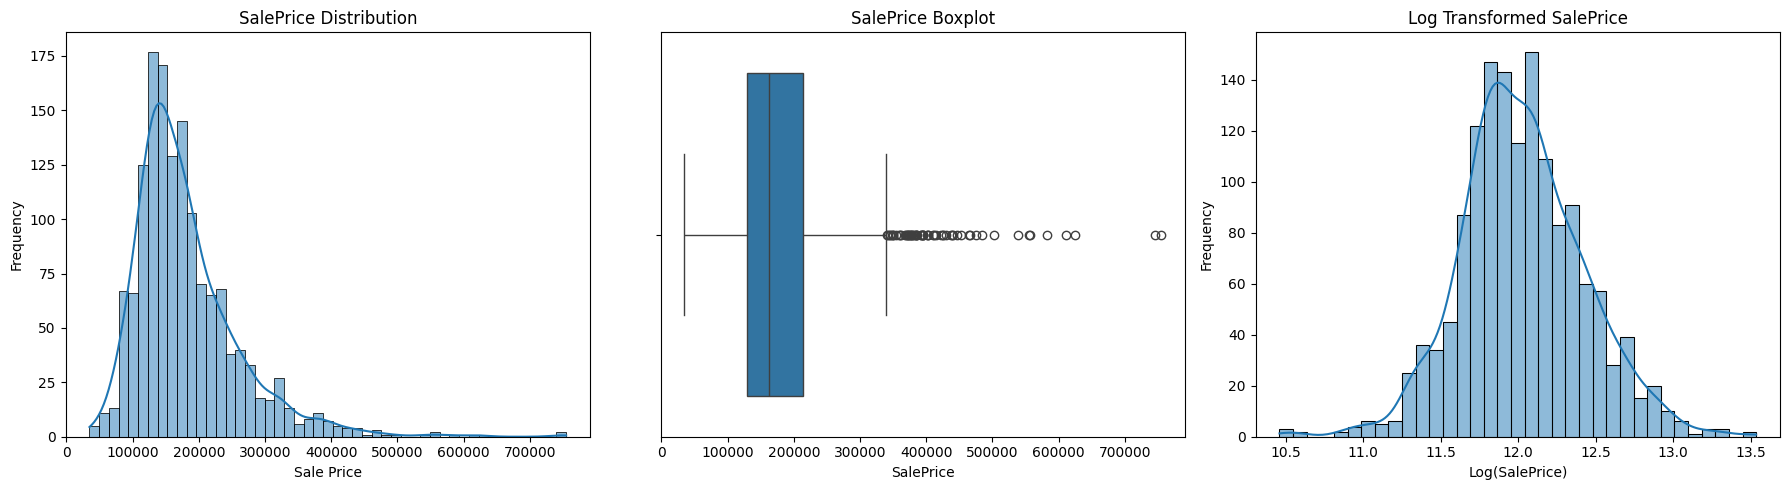

In [39]:

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Histogram with KDE
sns.histplot(df['SalePrice'], kde=True, ax=axes[0])
axes[0].set_title('SalePrice Distribution')
axes[0].set_xlabel('Sale Price')
axes[0].set_ylabel('Frequency')

# 2. Boxplot
sns.boxplot(x=df['SalePrice'], ax=axes[1])
axes[1].set_title('SalePrice Boxplot')

# 3. Histogram after log transformation
sns.histplot(np.log1p(df['SalePrice']), kde=True, ax=axes[2])
axes[2].set_title('Log Transformed SalePrice')
axes[2].set_xlabel('Log(SalePrice)')
axes[2].set_ylabel('Frequency')

plt.tight_layout()
plt.show()


## Correlation and Covariance

In [40]:

cov_matrix = df.select_dtypes(include='number').cov()

display(cov_matrix)

corr_matrix = df.select_dtypes(include='number').corr(method='pearson')

display(corr_matrix)


saleprice_corr = corr_matrix['SalePrice'].drop('SalePrice')

top_corr = saleprice_corr.reindex(
    saleprice_corr.abs().sort_values(ascending=False).index
)

print("Top 10 features correlated with SalePrice:")
display(top_corr.head(10))

top_3_features = top_corr.head(3).index

for feature in top_3_features:

    covariance = cov_matrix.loc[feature, 'SalePrice']
    correlation = corr_matrix.loc[feature, 'SalePrice']

    print(f"\nFeature: {feature}")
    print("Covariance:", covariance)
    print("Correlation:", correlation)

ordinal_df = df.copy()

ordinal_df['ExterQual'] = ordinal_df['ExterQual'].cat.codes
ordinal_df['KitchenQual'] = ordinal_df['KitchenQual'].cat.codes

spearman_corr = ordinal_df[
    ['SalePrice', 'OverallQual', 'ExterQual', 'KitchenQual']
].corr(method='spearman')

display(spearman_corr)



,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,177755.000000,198.968472,-108.390207,-1.398197e+05,-16.539068,5.915696,-1.618818e+02,-191.474297,-3.842688e+03,-9.661021e+02,...,-1.566468e+03,-1.332214e+01,74.450651,-576.428376,31.270391,966.275531,-1305.726525,24.133653,0.398561,-7.340732e+05
MSSubClass,198.968472,1789.338306,-404.439075,-5.901742e+04,1.908771,-2.792117,3.558134e+01,35.439934,1.758378e+02,-1.347356e+03,...,-6.669453e+01,-1.709661e+01,-31.119180,-54.348569,-61.394007,14.076652,-161.243759,-1.553607,-1.202630,-2.832337e+05
LotFrontage,-108.390207,-404.439075,589.749169,8.199814e+04,8.673047,-1.573935,9.510848e+01,45.744675,8.712074e+02,2.635953e+03,...,2.587889e+02,2.438681e+02,16.022614,48.936214,56.264418,194.586364,15.520479,0.735389,0.240700,7.124262e+05
LotArea,-139819.667238,-59017.418634,81998.138404,9.962565e+07,1460.548271,-62.602871,4.289113e+03,2841.343594,1.884014e+05,9.746908e+05,...,2.148006e+05,5.606253e+04,-11188.088772,5976.210971,24020.024881,31148.209380,188508.749657,32.517342,-189.050203,2.092111e+08
OverallQual,-16.539068,1.908771,8.673047,1.460548e+03,1.912679,-0.141484,2.390622e+01,15.723417,1.030121e+02,1.511770e+02,...,4.141573e+01,2.829764e+01,-9.630806,1.231398,5.003537,3.620945,-21.548945,0.264785,-0.050229,8.690413e+04
OverallCond,5.915696,-2.792117,-1.573935,-6.260287e+01,-0.141484,1.238322,-1.263671e+01,1.694152,-2.581896e+01,-2.346427e+01,...,-4.649741e-01,-2.402762e+00,4.785160,0.832039,3.400819,-0.088745,37.970669,-0.010563,0.064953,-6.882739e+03
YearBuilt,-161.881768,35.581337,95.108483,4.289113e+03,23.906215,-12.636709,9.122154e+02,369.675456,1.725993e+03,3.437028e+03,...,8.513053e+02,3.775838e+02,-714.886948,27.763434,-84.815514,6.006353,-515.209195,1.012426,-0.546237,1.254637e+06
YearRemodAdd,-191.474297,35.439934,45.744675,2.841344e+03,15.723417,1.694152,3.696755e+02,426.232822,6.716764e+02,1.209533e+03,...,5.323509e+02,3.095486e+02,-244.692937,27.410061,-44.594964,4.835329,-105.358566,1.199517,0.980046,8.317079e+05
MasVnrArea,-3842.687941,175.837842,871.207424,1.884014e+05,103.012054,-25.818956,1.725993e+03,671.676358,3.278497e+04,2.182760e+04,...,3.626330e+03,1.503301e+03,-1218.999064,100.044636,622.125969,85.516034,-2685.666442,-2.915638,-1.973363,6.854858e+06
BsmtFinSF1,-966.102125,-1347.355751,2635.952669,9.746908e+05,151.176998,-23.464270,3.437028e+03,1209.532821,2.182760e+04,2.080255e+05,...,1.167953e+04,3.377322e+03,-2851.840396,353.685020,1577.237193,2574.473738,808.155748,-19.393195,8.697797,1.400137e+07


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,1.000000,0.011156,-0.010601,-0.033226,-0.028365,0.012609,-0.012713,-0.021998,-0.050298,-0.005024,...,-0.029643,-0.000477,0.002889,-0.046635,0.001330,0.057044,-0.006242,0.021172,0.000712,-0.021917
MSSubClass,0.011156,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,...,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.010601,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,...,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,-0.033226,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,...,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,-0.028365,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,...,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982
OverallCond,0.012609,-0.059316,-0.059213,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.128101,-0.046231,...,-0.003334,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856
YearBuilt,-0.012713,0.027850,0.123349,0.014228,0.572323,-0.375983,1.000000,0.592855,0.315707,0.249503,...,0.224880,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897
YearRemodAdd,-0.021998,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,...,0.205726,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101
MasVnrArea,-0.050298,0.022936,0.193458,0.104160,0.411876,-0.128101,0.315707,0.179618,1.000000,0.264736,...,0.159718,0.125703,-0.110204,0.018796,0.061466,0.011723,-0.029815,-0.005965,-0.008201,0.477493
BsmtFinSF1,-0.005024,-0.069836,0.233633,0.214103,0.239666,-0.046231,0.249503,0.128451,0.264736,1.000000,...,0.204306,0.111761,-0.102303,0.026451,0.062021,0.140491,0.003571,-0.015727,0.014359,0.386420


Top 10 features correlated with SalePrice:


,SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101



Feature: OverallQual
Covariance: 86904.12583679946
Correlation: 0.7909816005838053

Feature: GrLivArea
Covariance: 29581866.743236575
Correlation: 0.7086244776126515

Feature: GarageCars
Covariance: 38020.18135897172
Correlation: 0.6404091972583519


,SalePrice,OverallQual,ExterQual,KitchenQual
SalePrice,1.000000,0.809829,0.684014,0.672849
OverallQual,0.809829,1.000000,0.715988,0.660498
ExterQual,0.684014,0.715988,1.000000,0.725266
KitchenQual,0.672849,0.660498,0.725266,1.000000


Correlation is not causation. Name one pair of features that are correlated with each other (for example GarageArea and GarageCars) and explain why that matters.

## Scatter Plots and Pair Plots

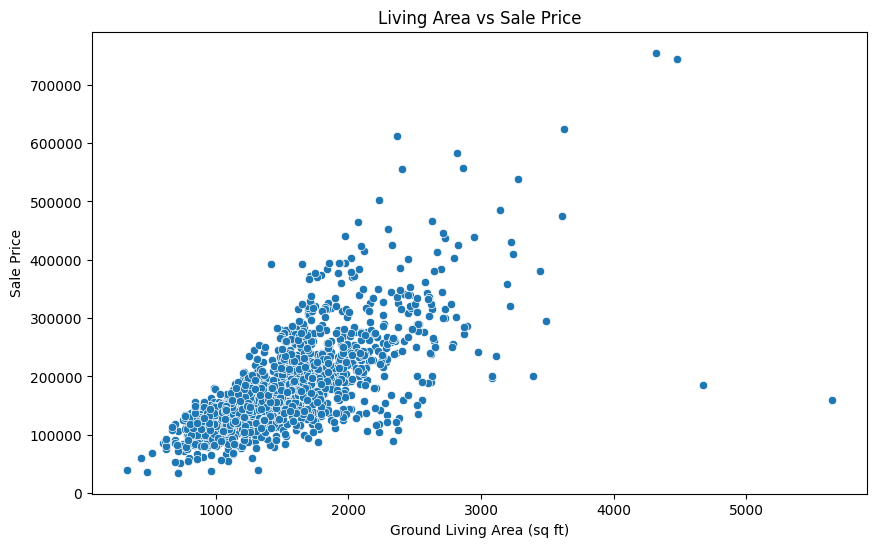

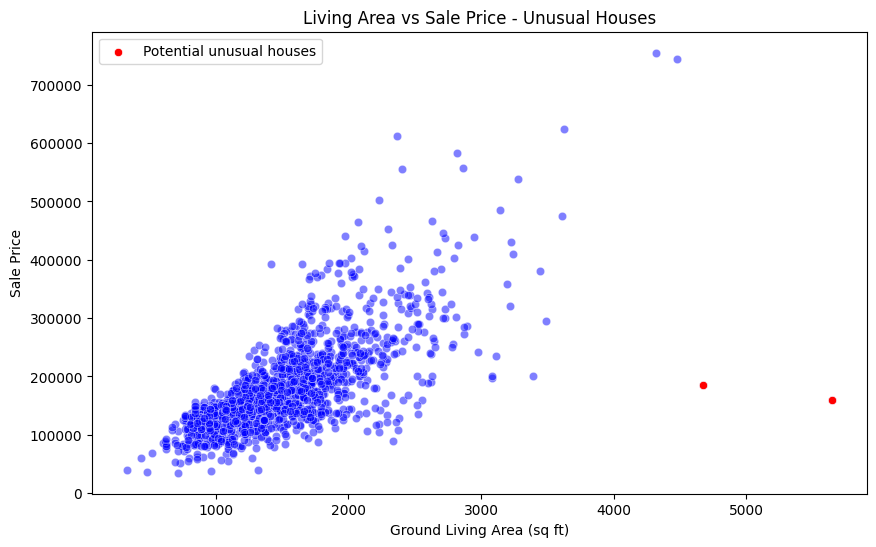

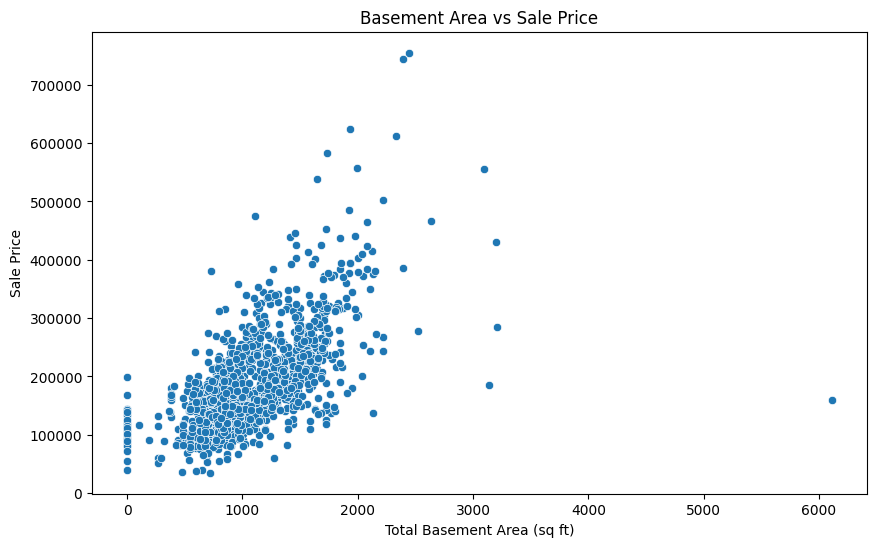

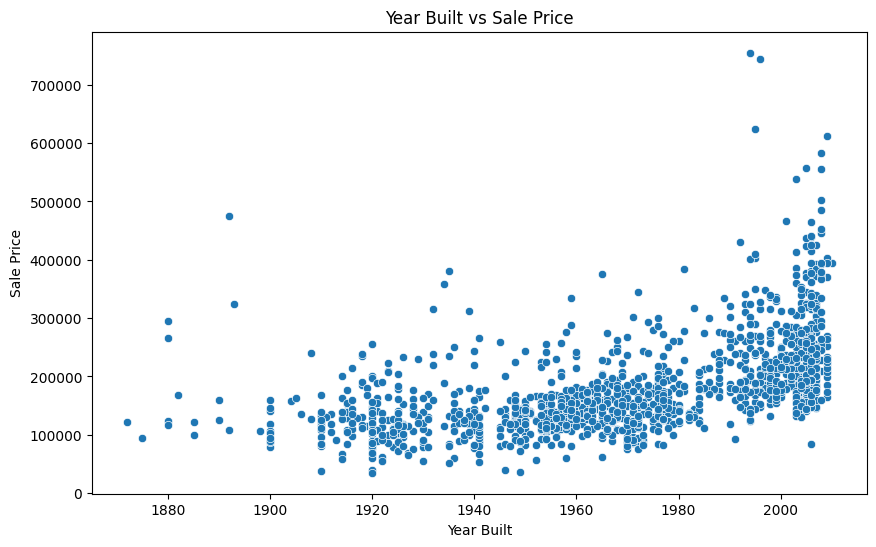

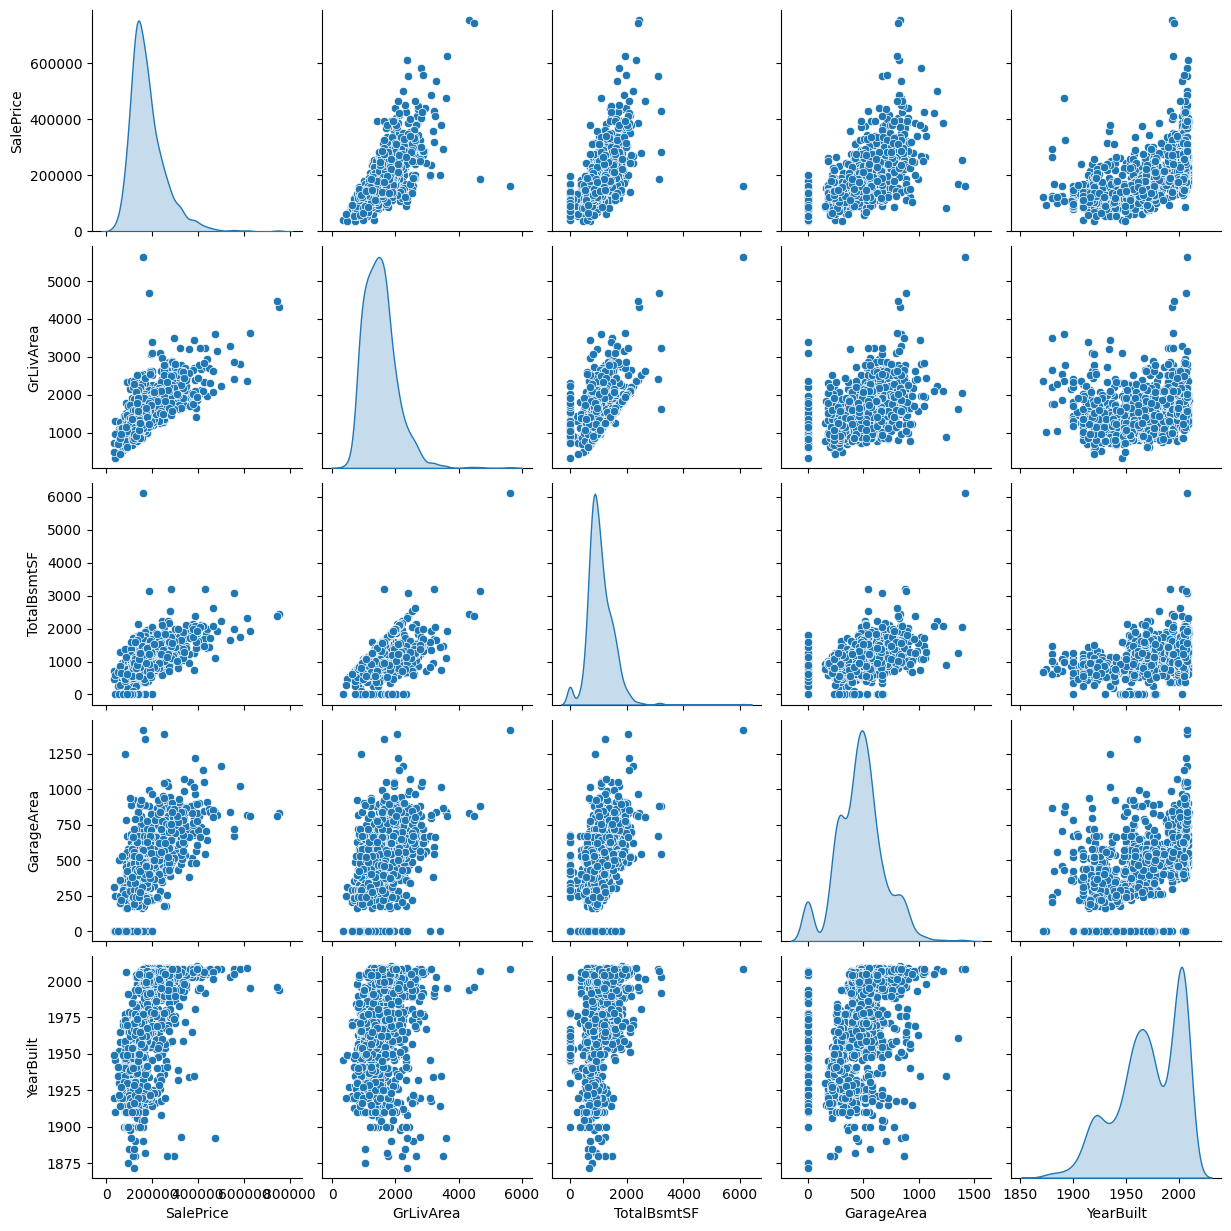

In [41]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x='GrLivArea',
    y='SalePrice',
    data=df
)

plt.title('Living Area vs Sale Price')
plt.xlabel('Ground Living Area (sq ft)')
plt.ylabel('Sale Price')

plt.show()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x='GrLivArea',
    y='SalePrice',
    data=df,
    color='blue',
    alpha=0.5
)

unusual = df[
    (df['GrLivArea'] > 4000) &
    (df['SalePrice'] < 200000)
]

sns.scatterplot(
    x='GrLivArea',
    y='SalePrice',
    data=unusual,
    color='red',
    label='Potential unusual houses'
)

plt.title('Living Area vs Sale Price - Unusual Houses')
plt.xlabel('Ground Living Area (sq ft)')
plt.ylabel('Sale Price')
plt.legend()

plt.show()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x='TotalBsmtSF',
    y='SalePrice',
    data=df
)

plt.title('Basement Area vs Sale Price')
plt.xlabel('Total Basement Area (sq ft)')
plt.ylabel('Sale Price')

plt.show()

plt.figure(figsize=(10, 6))

sns.scatterplot(
    x='YearBuilt',
    y='SalePrice',
    data=df
)

plt.title('Year Built vs Sale Price')
plt.xlabel('Year Built')
plt.ylabel('Sale Price')

plt.show()

selected = [
    'SalePrice',
    'GrLivArea',
    'TotalBsmtSF',
    'GarageArea',
    'YearBuilt'
]

sns.pairplot(
    df[selected],
    diag_kind='kde'
)

plt.show()
